# Modellierung

## Init

In [3]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Datenselektierung

In [4]:
display(df.head())

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,year,month,...,day_of_month,week_of_year,day_of_year,is_weekend,unix_ts_date,needed_personal,calls_per_duty,call_stress,sby_used_percent,season
0,2016-04-01,73,8154.0,1700,90,4.0,0.0,False,2016,4,...,1,13,92,False,1459468800,1631.0,4.796471,4.785211,4.444444,1
1,2016-04-02,64,8526.0,1700,90,70.0,0.0,False,2016,4,...,2,13,93,True,1459555200,1706.0,5.015294,4.816949,77.777778,1
2,2016-04-03,68,8088.0,1700,90,0.0,0.0,False,2016,4,...,3,13,94,True,1459641600,1632.0,4.757647,4.757647,0.000000,1
3,2016-04-04,71,7044.0,1700,90,0.0,0.0,False,2016,4,...,4,14,95,False,1459728000,1629.0,4.143529,4.143529,0.000000,1
4,2016-04-05,63,7236.0,1700,90,0.0,0.0,False,2016,4,...,5,14,96,False,1459814400,1637.0,4.256471,4.256471,0.000000,1


In [5]:
print(df.columns)

Index(['date', 'n_sick', 'calls', 'n_duty', 'n_sby', 'sby_need', 'dafted',
       'is_holiday', 'year', 'month', 'day_of_week', 'day_of_month',
       'week_of_year', 'day_of_year', 'is_weekend', 'unix_ts_date',
       'needed_personal', 'calls_per_duty', 'call_stress', 'sby_used_percent',
       'season'],
      dtype='object')


In [6]:

# List der Spalten, die nicht benutzt werden sollen, da sie u. a. zur Anwendungszeit nicht zur Verfügung stehen und daher auch nicht als Features genutzt werden können oder
excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "unix_ts_date", "needed_personal"]

usable_columns = list(set(df.columns) - set(excluded_columns))

#Overwrite usable_columns to force certain scenario
#usable_columns = ["unix_ts_date"]                                                                                               # R2: 44% (this and all below only works for shuffled data)
#usable_columns = ["unix_ts_date", "year", "month", "week_of_year", "day_of_year", "is_weekend", "is_holiday", "day_of_week"]           # R2: 51,1% 
#usable_columns = ["month", "day_of_year"]                                                                                      # R2: 22%
#usable_columns = ["year", "day_of_year"]                                                                                       # R2: 44%
#usable_columns = ["unix_ts_date", "month"]                                                                                     # R2: 45%
#usable_columns = ["unix_ts_date", "month", "day_of_year"]                                                                      # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend"]                                                                                 # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend", "is_holiday", "day_of_week", "month"]                                                                   # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend", "calls_ma_7_lag_30"]                                                                   # R2: 
#usable_columns = ["calls_ma_8_lag_1", "unix_ts_date"]
#usable_columns = ["week_of_year", "day_of_week", "is_holiday", "is_weekend"]

target_column = 'sby_need'

print("Usable columns:", usable_columns)

Usable columns: ['is_weekend', 'day_of_month', 'n_duty', 'season', 'is_holiday', 'day_of_year', 'week_of_year', 'year', 'day_of_week', 'n_sby', 'month']


In [7]:
from sklearn.model_selection import train_test_split


# Prepare features and target
X = df[usable_columns]

#X = df[['n_duty', 'season', 'month', 'day_of_week', 'is_holiday', 'is_weekend']] #auf faktoren beschränkt, die man zu dem Zeitpunkt der Planung wissen kann

y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False) # shuffle = False um Daten Ordnung beizubehalten

# Modellierungvergleiche

In [8]:
# Modelle für Nutzung

from sklearn.ensemble import StackingRegressor, RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import BaggingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Zusätzliche Modelle, die nicht aus sklearn stammen
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [9]:
models = {
    # 'StackingRegressor': StackingRegressor(
    #     estimators=[
    #         ('lr', LinearRegression()),
    #         ('dt', DecisionTreeRegressor(max_depth=10, min_samples_split=10, min_samples_leaf=5)),
    #         ('svr', SVR(C=10, kernel='rbf', gamma='scale'))
    #     ],
    #     final_estimator=Ridge(alpha=1.0),
    #     cv=5,
    #     n_jobs=-1
    # ),
    
    # 'StackingRegressor_2': StackingRegressor(
    #     estimators=[
    #         ('gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)),
    #         ('nn', MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1500, random_state=42)),
    #         ('knn', KNeighborsRegressor(n_neighbors=7, weights='distance', p=2))
    #     ],
    #     final_estimator=Ridge(alpha=1.0),
    #     cv=5,
    #     n_jobs=-1
    # ),
    
    'Linear Regression': LinearRegression(),
    
    # 'Decision Tree': DecisionTreeRegressor(
    #     max_depth=10, 
    #     min_samples_split=10, 
    #     min_samples_leaf=5, 
    #     random_state=42
    # ),
    
    'Random Forest': RandomForestRegressor(
        n_estimators=200, 
        max_depth=10, 
        min_samples_split=10, 
        min_samples_leaf=5, 
        bootstrap=True, 
        random_state=42, 
        n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200, 
        learning_rate=0.05, 
        max_depth=4, 
        subsample=0.8, 
        random_state=42
    ),
    
    # 'Support Vector Machine': SVR(
    #     C=10, 
    #     kernel='rbf', 
    #     gamma='scale'
    # ),
    
    #'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=7, weights='distance', p=2),
    
    'Lasso Regression': Lasso(
        alpha=0.01, 
        max_iter=1000, 
        random_state=42
    ),
    
    'Ridge Regression': Ridge(
        alpha=1.0, 
        random_state=42
    ),
    
    'XGBoost': XGBRegressor(
        n_estimators=200, 
        learning_rate=0.05, 
        max_depth=4, 
        subsample=0.8, 
        colsample_bytree=0.8, 
        random_state=42, 
        n_jobs=-1
    ),
    
    # Polynomial Regression
    'Polynomial Regression (10)': Pipeline([
        ('poly', PolynomialFeatures(degree=10)),
        ('linear', LinearRegression())
    ]),
    
    'Polynomial Ridge Regression (8)': Pipeline([
        ('poly', PolynomialFeatures(degree=8)),
        ('ridge', Ridge(alpha=1.0))
    ]),

    'Polynomial Lasso Regression (8)': Pipeline([
        ('poly', PolynomialFeatures(degree=8)),
        ('lasso', Lasso(alpha=0.01, max_iter=1000, random_state=42))
    ]),

    'LightGBM': LGBMRegressor(
        n_estimators=200, 
        learning_rate=0.05, 
        num_leaves=31, 
        max_depth=-1, 
        min_child_samples=20, 
        subsample=0.8, 
        colsample_bytree=0.8, 
        random_state=42
    ),
    # 'Bagging Regressor': BaggingRegressor(
    #     n_estimators=50,
    #     random_state=42,
    #     n_jobs=-1
    # ),
    
    # 'HistGradient Boosting': HistGradientBoostingRegressor(
    #     loss='absolute_error',
    #     learning_rate=0.05,
    #     max_iter=100,
    #     max_depth=4,
    #     random_state=42
    # )
}


In [10]:
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "MAPE" : mape, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "MAPE" : {mape}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 60.364853678192524, MSE: 10421.868685958612, RMSE: 102.08755402084337, R2: 0.07813773622309483, "MAPE" : 7.926954083741594e+16, "Training Time (s)" : 0.0054438114166259766
Random Forest - MAE: 50.19309996362678, MSE: 10158.690983880244, RMSE: 100.79033179764934, R2: 0.10141701554662363, "MAPE" : 2.3740513904844316e+16, "Training Time (s)" : 0.2149491310119629
Gradient Boosting - MAE: 61.9434957113687, MSE: 10565.666096951167, RMSE: 102.78942599777064, R2: 0.06541819322967235, "MAPE" : 8.358417274750352e+16, "Training Time (s)" : 0.19851422309875488


/usr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.959e+06, tolerance: 4.596e+02
  model = cd_fast.enet_coordinate_descent(


Lasso Regression - MAE: 63.012016319681365, MSE: 11397.418757346331, RMSE: 106.7586940597642, R2: -0.008154158669887446, "MAPE" : 8.037754941029198e+16, "Training Time (s)" : 0.014390230178833008
Ridge Regression - MAE: 61.896725852065735, MSE: 10704.709420269071, RMSE: 103.46356566574086, R2: 0.053119171177168245, "MAPE" : 8.425501244443768e+16, "Training Time (s)" : 0.0043299198150634766
XGBoost - MAE: 58.745415512182106, MSE: 10393.02827172905, RMSE: 101.94620283134164, R2: 0.08068880363250763, "MAPE" : 6.620435848443923e+16, "Training Time (s)" : 0.13296985626220703
Polynomial Regression (10) - MAE: 928292078884.0109, MSE: 1.3466611899857916e+24, RMSE: 1160457319329.6648, R2: -1.1911838179398576e+20, "MAPE" : 2.434220054574839e+27, "Training Time (s)" : 252.75469493865967


/usr/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(


Polynomial Ridge Regression (8) - MAE: 146.97878183936277, MSE: 36252.45948751213, RMSE: 190.40078646768276, R2: -2.206696934846718, "MAPE" : 5.175820148124581e+17, "Training Time (s)" : 34.7331337928772
Polynomial Lasso Regression (8) - MAE: 60.80704133986731, MSE: 10125.593079422117, RMSE: 100.62600597967763, R2: 0.10434467756669397, "MAPE" : 9.233003504864312e+16, "Training Time (s)" : 67.9295654296875
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004287 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 374
[LightGBM] [Info] Number of data points in the train set: 921, number of used features: 9
[LightGBM] [Info] Start training from score 29.994571
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LightGBM - MAE: 52.840536696667364, MSE: 10125.786885236332, RMSE: 100.62696897569921, R2: 0.10432753455021504, "MAPE" : 3.866725693049975e+16, "Training Time (s)" : 0.085565328

/usr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.338e+06, tolerance: 4.596e+02
  model = cd_fast.enet_coordinate_descent(


In [11]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

sorted_by = 'R2'

# For R2 it has to be desending
results_df_sorted = results_df.sort_values(by=sorted_by, ascending=False)

print(f"Models sorted by {sorted_by}:")
display(results_df_sorted)

# Select the best model
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Models sorted by R2:


,MAE,MSE,RMSE,R2,MAPE,Training Time
Polynomial Lasso Regression (8),6.080704e+01,1.012559e+04,1.006260e+02,1.043447e-01,9.233004e+16,67.929565
LightGBM,5.284054e+01,1.012579e+04,1.006270e+02,1.043275e-01,3.866726e+16,0.085565
Random Forest,5.019310e+01,1.015869e+04,1.007903e+02,1.014170e-01,2.374051e+16,0.214949
XGBoost,5.874542e+01,1.039303e+04,1.019462e+02,8.068880e-02,6.620436e+16,0.132970
Linear Regression,6.036485e+01,1.042187e+04,1.020876e+02,7.813774e-02,7.926954e+16,0.005444
Gradient Boosting,6.194350e+01,1.056567e+04,1.027894e+02,6.541819e-02,8.358417e+16,0.198514
Ridge Regression,6.189673e+01,1.070471e+04,1.034636e+02,5.311917e-02,8.425501e+16,0.004330
Lasso Regression,6.301202e+01,1.139742e+04,1.067587e+02,-8.154159e-03,8.037755e+16,0.014390
Polynomial Ridge Regression (8),1.469788e+02,3.625246e+04,1.904008e+02,-2.206697e+00,5.175820e+17,34.733134
Polynomial Regression (10),9.282921e+11,1.346661e+24,1.160457e+12,-1.191184e+20,2.434220e+27,252.754695


Best Model: Polynomial Lasso Regression (8)
MAE              6.080704e+01
MSE              1.012559e+04
RMSE             1.006260e+02
R2               1.043447e-01
MAPE             9.233004e+16
Training Time    6.792957e+01
Name: Polynomial Lasso Regression (8), dtype: float64


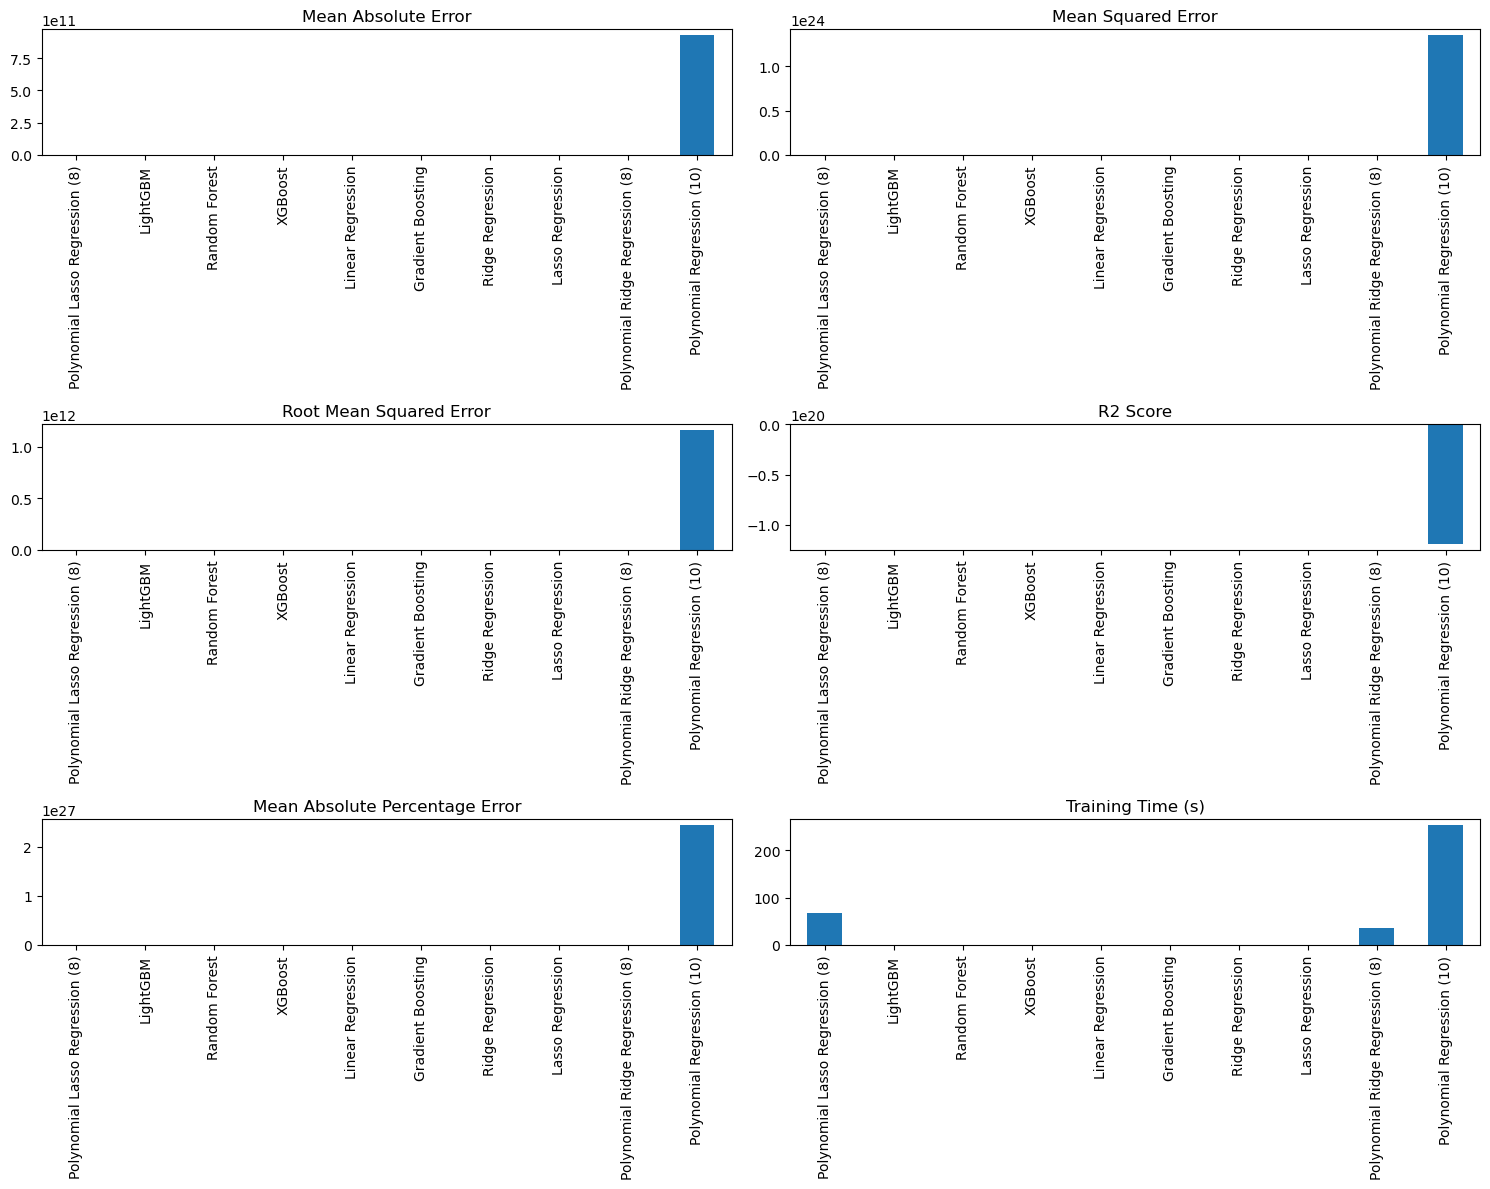

In [12]:
import matplotlib.pyplot as plt

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['MAPE'].plot(kind='bar', ax=axes[2, 0], title='Mean Absolute Percentage Error')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 1], title='Training Time (s)')
plt.tight_layout()
plt.show()

No Hyperparameter-Tuning because there is no template
Final Evaluation of the Best Model (Polynomial Lasso Regression (8)):
MAE: 60.80704133986731, MSE: 10125.593079422117, RMSE: 100.62600597967763, R2: 0.10434467756669397


/usr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.338e+06, tolerance: 4.596e+02
  model = cd_fast.enet_coordinate_descent(


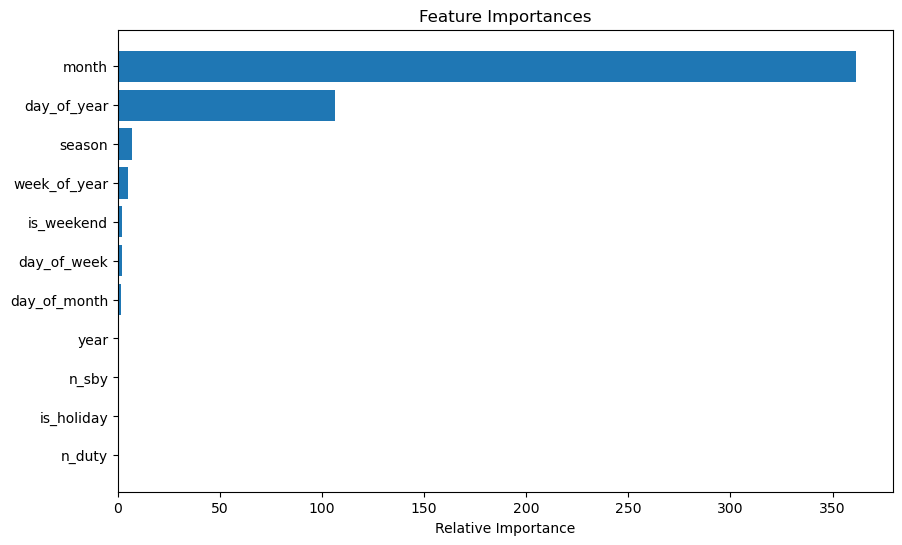

In [13]:
from sklearn.model_selection import GridSearchCV

# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

elif best_model_name == 'Lasso Regression':

    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1, 10, 100],  # Verschiedene Werte für den Regularisierungsparameter
        'max_iter': [1000, 5000, 10000],          # Maximale Anzahl an Iterationen
        'tol': [1e-4, 1e-3, 1e-2]                 # Toleranz für die Optimierung
    }

    grid_search = GridSearchCV(Lasso(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, scoring='r2', verbose=1)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

#elif best_model_name == 'StackingRegressor':
    # Do new stuff here
else:
    print("No Hyperparameter-Tuning because there is no template")
    best_model = models[best_model_name]

# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')

features = X.columns

if hasattr(best_model, "feature_importances_"):
    # Feature Importance for the best model
    importances = best_model.feature_importances_
elif hasattr(best_model, "coef_"):
    importances = np.argsort(np.abs(best_model.coef_))
else: 
    from sklearn.inspection import permutation_importance
    perm_importance = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
    importances = perm_importance.importances_mean
        

indices = np.argsort(importances)
plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

In [14]:
top_features = [features[i] for i in indices][-5:]

top_features.reverse()

display(top_features)

['month', 'day_of_year', 'season', 'week_of_year', 'is_weekend']

# Modell mit weniger Features (nur die wichtigsten)

In [15]:
additional_columns = ["date", "n_sick", "sby_need", "n_sby", "n_duty"]

X = df[top_features + additional_columns ]
y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

best_model.fit(X_train[top_features], y_train)

y_pred_best = best_model.predict(X_test[top_features])

mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)
mape = mean_absolute_percentage_error(y_test, y_pred_best)

print(f'MAPE: {mape}, MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')

MAPE: 5.372427346823232e+16, MAE: 56.76802497045005, MSE: 13024.324922663416, RMSE: 114.12416449930056, R2: -0.15206149867815966


/usr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.745e+06, tolerance: 4.596e+02
  model = cd_fast.enet_coordinate_descent(


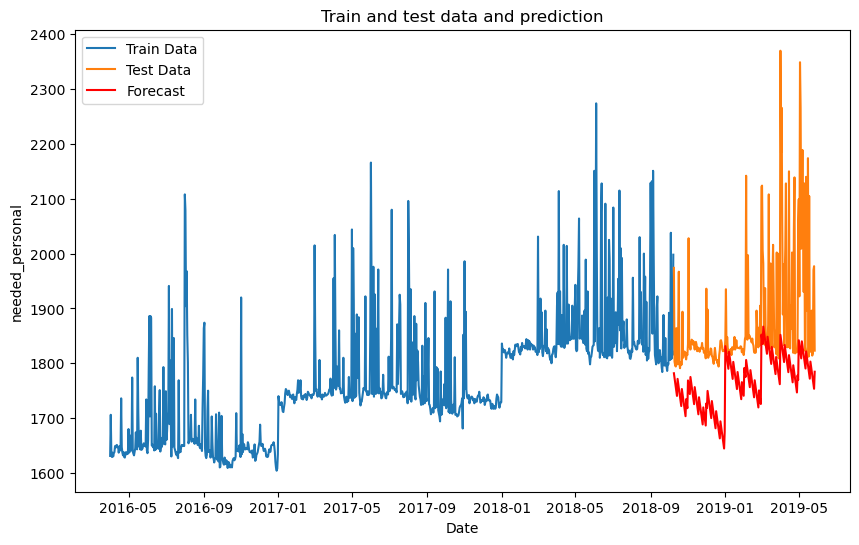

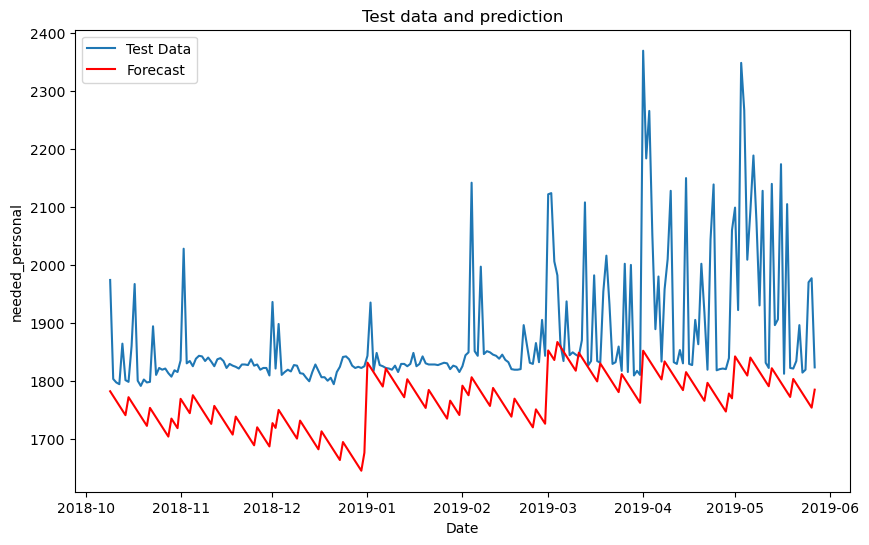

In [96]:
plt.figure(figsize=(10, 6))
plt.plot(X_train["date"], y_train, label='Train Data')
plt.plot(X_test["date"], y_test, label='Test Data')
plt.plot(X_test["date"], y_pred_best, label='Forecast', color='red')
plt.title('Train and test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(X_test["date"], y_test, label='Test Data')
plt.plot(X_test["date"], y_pred_best, label='Forecast', color='red')
plt.title('Test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

# Prediction Test

In [97]:
validation_df = pd.merge(X_test, y_test, left_index=True, right_index=True)

validation_df = validation_df.rename(columns={target_column : "orig_" + target_column})

display(validation_df)

,day_of_week,season,day_of_year,day_of_month,month,date,n_sick,sby_need,n_sby,n_duty,orig_needed_personal
921,1,3,282,9,10,2018-10-09,97,171.0,90,1900,1974.0
922,2,3,283,10,10,2018-10-10,97,0.0,90,1900,1803.0
923,3,3,284,11,10,2018-10-11,103,0.0,90,1900,1797.0
924,4,3,285,12,10,2018-10-12,106,0.0,90,1900,1794.0
925,5,3,286,13,10,2018-10-13,93,57.0,90,1900,1864.0
...,...,...,...,...,...,...,...,...,...,...,...
1147,3,1,143,23,5,2019-05-23,86,0.0,90,1900,1814.0
1148,4,1,144,24,5,2019-05-24,81,0.0,90,1900,1819.0
1149,5,1,145,25,5,2019-05-25,76,146.0,90,1900,1970.0
1150,6,1,146,26,5,2019-05-26,83,160.0,90,1900,1977.0


In [98]:
validation_df[target_column] = best_model.predict(validation_df[top_features])
display(validation_df)

,day_of_week,season,day_of_year,day_of_month,month,date,n_sick,sby_need,n_sby,n_duty,orig_needed_personal,needed_personal
921,1,3,282,9,10,2018-10-09,97,171.0,90,1900,1974.0,1781.754971
922,2,3,283,10,10,2018-10-10,97,0.0,90,1900,1803.0,1773.491851
923,3,3,284,11,10,2018-10-11,103,0.0,90,1900,1797.0,1765.228731
924,4,3,285,12,10,2018-10-12,106,0.0,90,1900,1794.0,1756.965611
925,5,3,286,13,10,2018-10-13,93,57.0,90,1900,1864.0,1748.702491
...,...,...,...,...,...,...,...,...,...,...,...,...
1147,3,1,143,23,5,2019-05-23,86,0.0,90,1900,1814.0,1778.221263
1148,4,1,144,24,5,2019-05-24,81,0.0,90,1900,1819.0,1769.958143
1149,5,1,145,25,5,2019-05-25,76,146.0,90,1900,1970.0,1761.695023
1150,6,1,146,26,5,2019-05-26,83,160.0,90,1900,1977.0,1753.431903


# Berechnen von n_sby aus Calls

In [99]:
validation_df = validation_df.rename(columns={"sby_need" : "orig_sby_need"})

In [100]:
validation_df["total_personal"] = validation_df.apply(lambda row: (row.calls / 5), axis=1)
validation_df["total_personal_based_on_orig_calls"] = validation_df.apply(lambda row: (row.orig_calls / 5), axis=1)

AttributeError: 'Series' object has no attribute 'calls'

In [ ]:
validation_df.describe()

,week_of_year,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls
count,231.000000,231.000000,231,231.000000,231.000000,231.0,231.0,231.000000,231.000000,231.000000,231.000000
mean,23.826840,3.000000,2019-02-01 00:00:00,75.718615,53.554113,90.0,1900.0,8473.532468,7789.756159,1557.951232,1694.706494
min,1.000000,0.000000,2018-10-09 00:00:00,49.000000,0.000000,90.0,1900.0,5760.000000,7217.562484,1443.512497,1152.000000
25%,9.000000,1.000000,2018-12-05 12:00:00,68.500000,0.000000,90.0,1900.0,7509.000000,7457.841603,1491.568321,1501.800000
50%,17.000000,3.000000,2019-02-01 00:00:00,75.000000,0.000000,90.0,1900.0,8502.000000,7876.884892,1575.376978,1700.400000
75%,44.000000,5.000000,2019-03-30 12:00:00,82.000000,56.500000,90.0,1900.0,9336.000000,8023.113237,1604.622647,1867.200000
max,52.000000,6.000000,2019-05-27 00:00:00,109.000000,555.000000,90.0,1900.0,11850.000000,8241.896822,1648.379364,2370.000000
std,17.872383,2.004343,NaN,12.031609,106.556967,0.0,0.0,1297.897640,307.484867,61.496973,259.579528


In [ ]:
validation_df["sby_need_new"] = validation_df.apply(lambda row: row.total_personal - row.n_duty + row.n_sby , axis=1)
validation_df["sby_need_based_on_orig_calls"] = validation_df.apply(lambda row: row.total_personal_based_on_orig_calls - row.n_duty + row.n_sby, axis=1)

validation_df["sby_need_diff"] = validation_df.apply(lambda row:  row.sby_need_new - row.orig_sby_need, axis=1)

In [ ]:
display(validation_df)

,is_weekend,week_of_year,is_holiday,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls,sby_need_new,sby_need_based_on_orig_calls,sby_need_diff
921,False,41,False,1,2018-10-09,97,171.0,90,1900,9870.0,8012.590294,1602.518059,1974.0,-207.481941,164.0,-378.481941
922,False,41,False,2,2018-10-10,97,0.0,90,1900,7896.0,7908.684796,1581.736959,1579.2,-228.263041,-230.8,-228.263041
923,False,41,False,3,2018-10-11,103,0.0,90,1900,7302.0,7804.779299,1560.955860,1460.4,-249.044140,-349.6,-249.044140
924,False,41,False,4,2018-10-12,106,0.0,90,1900,7506.0,7700.873801,1540.174760,1501.2,-269.825240,-308.8,-269.825240
925,True,41,False,5,2018-10-13,93,57.0,90,1900,9318.0,7355.953265,1471.190653,1863.6,-338.809347,53.6,-395.809347
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,False,21,False,3,2019-05-23,86,0.0,90,1900,8544.0,7867.479814,1573.495963,1708.8,-236.504037,-101.2,-236.504037
1148,False,21,False,4,2019-05-24,81,0.0,90,1900,8814.0,7763.574317,1552.714863,1762.8,-257.285137,-47.2,-257.285137
1149,True,21,False,5,2019-05-25,76,146.0,90,1900,9846.0,7418.653781,1483.730756,1969.2,-326.269244,159.2,-472.269244
1150,True,21,False,6,2019-05-26,83,160.0,90,1900,9882.0,7314.748283,1462.949657,1976.4,-347.050343,166.4,-507.050343


In [ ]:
validation_df[["orig_sby_need", "sby_need_new", "sby_need_based_on_orig_calls"]]

,orig_sby_need,sby_need_new,sby_need_based_on_orig_calls
921,171.0,-207.481941,164.0
922,0.0,-228.263041,-230.8
923,0.0,-249.044140,-349.6
924,0.0,-269.825240,-308.8
925,57.0,-338.809347,53.6
...,...,...,...
1147,0.0,-236.504037,-101.2
1148,0.0,-257.285137,-47.2
1149,146.0,-326.269244,159.2
1150,160.0,-347.050343,166.4


In [ ]:
display(validation_df.sort_values("sby_need_diff", ascending=False))

,is_weekend,week_of_year,is_holiday,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls,sby_need_new,sby_need_based_on_orig_calls,sby_need_diff
1004,False,1,False,0,2018-12-31,75,0.0,90,1900,6318.0,8241.896822,1648.379364,1263.6,-161.620636,-546.4,-161.620636
1011,False,2,False,0,2019-01-07,78,0.0,90,1900,6798.0,8238.761796,1647.752359,1359.6,-162.247641,-450.4,-162.247641
1018,False,3,False,0,2019-01-14,75,0.0,90,1900,8118.0,8235.626771,1647.125354,1623.6,-162.874646,-186.4,-162.874646
1025,False,4,False,0,2019-01-21,72,0.0,90,1900,8430.0,8232.491745,1646.498349,1686.0,-163.501651,-124.0,-163.501651
1032,False,5,False,0,2019-01-28,80,0.0,90,1900,8994.0,8229.356719,1645.871344,1798.8,-164.128656,-11.2,-164.128656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1065,True,9,False,5,2019-03-02,60,284.0,90,1900,10620.0,7456.274090,1491.254818,2124.0,-318.745182,314.0,-602.745182
1097,False,14,False,2,2019-04-03,79,445.0,90,1900,11328.0,7993.330492,1598.666098,2265.6,-211.333902,455.6,-656.333902
1095,False,14,False,0,2019-04-01,85,555.0,90,1900,11850.0,8201.141487,1640.228297,2370.0,-169.771703,560.0,-724.771703
1128,True,18,False,5,2019-05-04,66,433.0,90,1900,11334.0,7428.058858,1485.611772,2266.8,-324.388228,456.8,-757.388228


In [ ]:
# validation_df["sby_need"] = validation_df.apply(lambda row: (row.total_personal - (row.n_duty + row.n_sick)), axis=1)

## Single prediction

In [ ]:
predict_data = pd.DataFrame([{
        'month' : 9,
        'day_of_week' : 3,
        'season' : 3,
        'n_sby_ma_35_lag_28' : 67,
        'day_of_year' : 266,
    }])


best_model.predict(predict_data)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- day_of_year
- month
- n_sby_ma_35_lag_28
- season
Feature names seen at fit time, yet now missing:
- is_holiday
- is_weekend
- week_of_year


# Export model

In [ ]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)